In [1]:
#peak flux = 51.109

#peak flux error = 2.5555148096812124

#day of peak flux = 11.05000000000291

#orbital period (hours) 747.6 days --> 17942.4 hours

#vpeak = 7.109

#velocity = 9094.68 km/s

In [1]:
#Get the imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

In [2]:
#The Radio data
V3890_radio = pd.read_csv('/Users/isabellamolina/PB_Works/V3890_Sgr.txt', delim_whitespace = True, header = 0)

freq = V3890_radio['Freq(GHz)']
flux = V3890_radio['Flux(mJy)']
err = V3890_radio['eFlux(mJy)']
MJD = V3890_radio['MJD']


/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_17932/4019309102.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  V3890_radio = pd.read_csv('/Users/isabellamolina/PB_Works/V3890_Sgr.txt', delim_whitespace = True, header = 0)


In [3]:
#TO = 58723 (August 28, 2019)
#JD=2458723.5000000

def MJD_to_date(MJD, first):
    days = []
    for i in range(len(MJD)):
        days.append(float(MJD[i]) - first)
    return(days)

day = np.array(MJD_to_date(MJD,58723))


In [4]:
#Sort data by freq and non detections 

A = np.logical_and(freq>= 0, freq<= 1.5) 
L_AC = np.where(np.logical_and(A, flux > 3*err)) 
L_nac = np.where(np.logical_and(A, flux < 3*err))

freq_LAC = np.ravel([freq[i] for i in L_AC])
flux_LAC = np.ravel([flux[i] for i in L_AC])
err_LAC  = np.ravel([err[i] for i in L_AC])
date_LAC = np.ravel([day[i] for i in L_AC])

nflux_LAC = np.ravel([flux[i] + err[i]*3 for i in L_nac])
ndate_LAC = np.ravel([day[i] for i in L_nac])


###############################################################
B = np.logical_and(freq>= 1.5, freq<= 2)
L_BD = np.where(np.logical_and(B, flux > 3*err)) 
L_nbd = np.where(np.logical_and(B, flux < 3*err))

freq_LBD = np.ravel([freq[i] for i in L_BD])
flux_LBD = np.ravel([flux[i] for i in L_BD])
err_LBD  = np.ravel([err[i] for i in L_BD])
date_LBD = np.ravel([day[i] for i in L_BD])

nflux_LBD = np.ravel([flux[i] + err[i]*3 for i in L_nbd])
ndate_LBD = np.ravel([day[i] for i in L_nbd])


###############################################################
C = np.logical_and(freq>= 3, freq<= 5)
C_AC = np.where(np.logical_and(C, flux > 3*err)) 
C_nac = np.where(np.logical_and(C, flux < 3*err))

freq_CAC = np.ravel([freq[i] for i in C_AC])
flux_CAC = np.ravel([flux[i] for i in C_AC])
err_CAC  = np.ravel([err[i] for i in C_AC])
date_CAC = np.ravel([day[i] for i in C_AC])

nflux_CAC = np.ravel([flux[i] + err[i]*3 for i in C_nac])
ndate_CAC = np.ravel([day[i] for i in C_nac])


###############################################################
D = np.logical_and(freq>= 6, freq<= 8) 
C_BD = np.where(np.logical_and(D, flux > 3*err)) 
C_nbd = np.where(np.logical_and(D, flux < 3*err))

freq_CBD = np.ravel([freq[i] for i in C_BD])
flux_CBD = np.ravel([flux[i] for i in C_BD])
err_CBD  = np.ravel([err[i] for i in C_BD])
date_CBD = np.ravel([day[i] for i in C_BD])

nflux_CBD = np.ravel([flux[i] + err[i]*3 for i in C_nbd])
ndate_CBD = np.ravel([day[i] for i in C_nbd])

###############################################################
E = np.logical_and(freq>= 10, freq<= 14)
Ku_AC =  np.where(np.logical_and(E, flux > 3*err))  
Ku_nac = np.where(np.logical_and(E, flux < 3*err))  

freq_K_AC = np.ravel([freq[i] for i in Ku_AC])
flux_K_AC = np.ravel([flux[i] for i in Ku_AC])
err_K_AC  = np.ravel([err[i] for i in Ku_AC])
date_K_AC = np.ravel([day[i] for i in Ku_AC])

nflux_K_AC = np.ravel([flux[i] + err[i]*3 for i in Ku_nac])
ndate_K_AC = np.ravel([day[i] for i in Ku_nac])
###############################################################
F = np.logical_and(freq>= 15, freq<= 20)
Ku_BD =  np.where(np.logical_and(F, flux > 3*err))  
Ku_nbd = np.where(np.logical_and(F, flux < 3*err))  

freq_K_BD = np.ravel([freq[i] for i in Ku_BD])
flux_K_BD = np.ravel([flux[i] for i in Ku_BD])
err_K_BD  = np.ravel([err[i] for i in Ku_BD])
date_K_BD = np.ravel([day[i] for i in Ku_BD])

nflux_K_BD = np.ravel([flux[i] + err[i]*3 for i in Ku_nbd])
ndate_K_BD = np.ravel([day[i] for i in Ku_nbd])
###############################################################

G = np.logical_and(freq>= 21, freq<= 30)
Ka_AC =  np.where(np.logical_and(G, flux > 3*err)) 
Ka_nac = np.where(np.logical_and(G, flux < 3*err)) 

freq_Ka_AC = np.ravel([freq[i] for i in Ka_AC])
flux_Ka_AC = np.ravel([flux[i] for i in Ka_AC])
err_Ka_AC  = np.ravel([err[i] for i in Ka_AC])
date_Ka_AC = np.ravel([day[i] for i in Ka_AC])

nflux_Ka_AC = np.ravel([flux[i] + err[i]*3 for i in Ka_nac])
ndate_Ka_AC = np.ravel([day[i] for i in Ka_nac])
###############################################################

H = np.logical_and(freq>= 31, freq<= 40)
Ka_BD =  np.where(np.logical_and(H, flux > 3*err))  
Ka_nbd = np.where(np.logical_and(H, flux < 3*err))

freq_Ka_BD = np.ravel([freq[i] for i in Ka_BD])
flux_Ka_BD = np.ravel([flux[i] for i in Ka_BD])
err_Ka_BD  = np.ravel([err[i] for i in Ka_BD])
date_Ka_BD = np.ravel([day[i] for i in Ka_BD])

nflux_Ka_BD = np.ravel([flux[i] + err[i]*3 for i in Ka_nbd])
ndate_Ka_BD = np.ravel([day[i] for i in Ka_nbd])

In [5]:
def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

In [6]:
#Error in Quadrature

quad_Lac = quad(err_LAC,freq_LAC, flux_LAC)  
quad_Lbd = quad(err_LBD,freq_LBD, flux_LBD)   
quad_Cac = quad(err_CAC,freq_CAC, flux_CAC)
quad_Cbd = quad(err_CBD,freq_CBD, flux_CBD)
quad_Kac = quad(err_K_AC,freq_K_AC, flux_K_AC)
quad_Kbd = quad(err_K_BD,freq_K_BD, flux_K_BD)
quad_Kaac = quad(err_Ka_AC,freq_Ka_AC, flux_Ka_AC)
quad_Kabd = quad(err_Ka_BD,freq_Ka_BD, flux_Ka_BD)


## Optical

In [7]:
#optical data input

V3890_opt_unflitered = pd.read_csv('V3890_Optical.txt', header = 0)

#now to get only the vband

column_name = 'Band'
key = 'V'

V3890_opt_kinda = V3890_opt_unflitered[V3890_opt_unflitered[column_name].str.contains(key, na=False)]

V3890_opt = V3890_opt_kinda[~V3890_opt_kinda[column_name].str.contains('Vis.|CV', na=False)]



In [8]:
#JD=2458723.5000000

opticaldays = np.array((V3890_opt['JD'].astype(float)) - 2458723.5000000)
vmag = np.array(V3890_opt['Magnitude'].astype(float))
error_vmag = V3890_opt['Uncertainty'].astype(float)

In [9]:
#find time to decline by 2 mag 
np.where(vmag > (np.min(vmag)+2.0)) 

vmag[2100]
opticaldays[2100]

1.8791200001724064

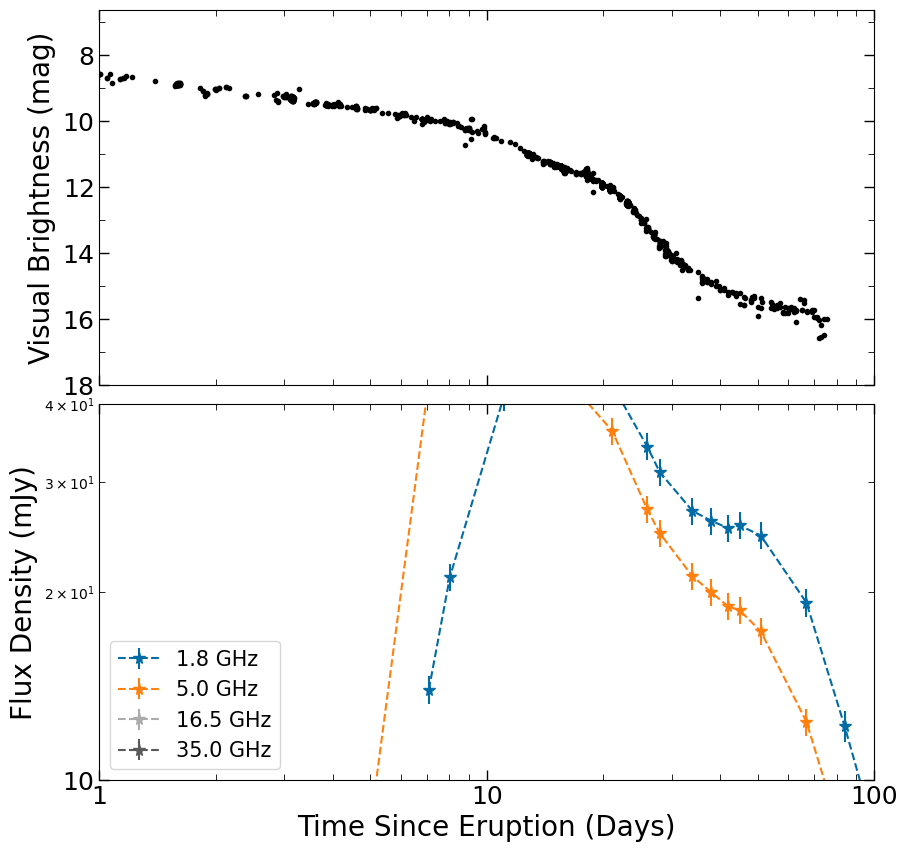

In [10]:
plt.style.use('tableau-colorblind10')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(2, 1, figsize=(10, 10), sharey=False, sharex = True)#, constrained_layout=True)


#first the visual
axs[0].scatter(opticaldays, vmag, marker = '.', color = 'black')
axs[0].annotate('V3890 Sgr',(130,8), fontsize=15)

axs[0].set_xscale('log')
#axs[0].set_yscale('log')

axs[0].set_ylabel('Visual Brightness (mag)',fontsize =20)

axs[0].set_yticks([8,10,12,14,16,18], labels = [r'$8$',r'$10$', r'$12$', r'$14$',r'$16$', r'$18$'], fontsize = 18)
axs[0].invert_yaxis()
axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


#now the radio
axs[1].set_ylabel('Flux Density (mJy)',fontsize=20)
axs[1].set_xlabel('Time Since Eruption (Days)', fontsize=20)
axs[1].set_xscale('log')
axs[1].set_yscale('log')



axs[1].errorbar(date_LBD, flux_LBD, yerr=quad_Lbd, linestyle ='--', fmt = '*' , markersize = 8.5, label='1.8 GHz')
axs[1].errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle ='--', fmt = '*', markersize = 8.5, label='5.0 GHz')
#axs[1].errorbar(date_CBD, flux_CBD, yerr=quad_Cbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='7.0 Ghz')
axs[1].errorbar(date_K_BD, flux_K_BD, yerr=quad_Kbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='16.5 GHz')
axs[1].errorbar(date_Ka_BD, flux_Ka_BD, yerr=quad_Kabd, linestyle ='--', fmt = '*' , markersize = 8.5, label='35.0 GHz')


axs[1].scatter(ndate_LBD, nflux_LBD, marker = 'v')
axs[1].scatter(ndate_CAC, nflux_CAC, marker = 'v')
#axs[1].scatter(ndate_CBD, nflux_CBD, marker = 'v')
axs[1].scatter(ndate_K_BD, nflux_K_BD , marker = 'v')
axs[1].scatter(ndate_Ka_BD, nflux_Ka_BD , marker = 'v')


axs[1].legend(fontsize=15, loc='lower left')

axs[1].set_xticks([0.1,1,10,100,500], labels = ['0.1','1','10','100','500'], fontsize = 18)
axs[1].set_xlim([1,100])

axs[1].set_yticks([0.01,0.1,1.0,10], labels = [r'$0.01$',r'$0.1$',r'$1$',r'$10$'], fontsize = 18)
axs[1].set_ylim([10,40])

axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)


fig.subplots_adjust(hspace=0.05)
plt.savefig("V3890Sgr_RadioOptical_lightcurves.png")
plt.show();

In [11]:
#Add spectral index plot 

si_d = [7.2,8.1,11.2,14.1,16.1,21.2,26.1,28.1,34,38.1,42.1,45.0,51.1,67,83.9,88,104.9,129.8,182.6,224.5,267.4,327.3,405.1,535.7]
si = [1.30,0.90,0.29,0,-0.06,-0.19,-0.28, -0.28, -0.32,-0.34,-0.36,-0.38,-0.41,-0.42,-0.40,-0.39,-0.44,-0.32,-0.28,-0.10,-0.32,-0.11,-0.41,-0.63]
si_e = [0.35,0.22,0.11,0.05,0.03,0.02,0.02,0.03,0.04,0.04,0.03,0.03,0.03,0.01,0.04,0.03,0.03,0.01,0.05,0.06,0.07,0.07,0.11,0.01]


In [15]:
si[21]

-0.11

In [26]:
si_d[21]

327.3

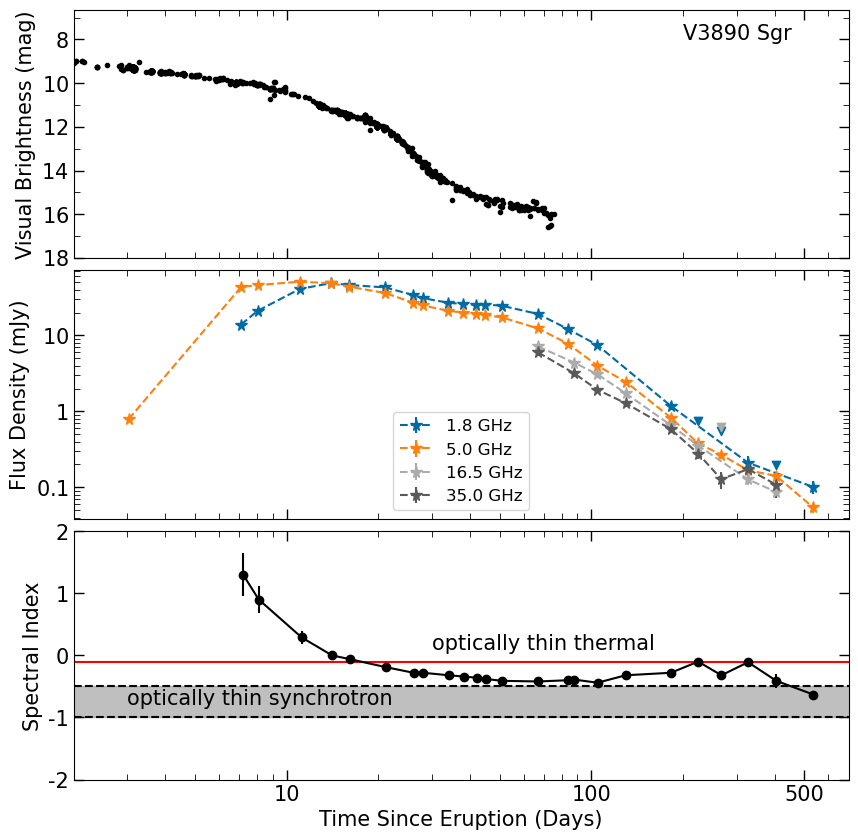

In [20]:
plt.style.use('tableau-colorblind10')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=False, sharex = True)


########### Panel 1 ############
axs[0].scatter(opticaldays, vmag, marker = '.', color = 'black')
axs[0].annotate('V3890 Sgr',(200,8), fontsize=15)

axs[0].set_xscale('log')
axs[0].set_ylabel('Visual Brightness (mag)',fontsize =15)

axs[0].set_yticks([8,10,12,14,16,18], labels = [r'$8$',r'$10$', r'$12$', r'$14$',r'$16$', r'$18$'], fontsize = 15)
axs[0].invert_yaxis()
axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


########### Panel 2 ############
axs[1].set_ylabel('Flux Density (mJy)',fontsize=15)
axs[1].set_xscale('log')
axs[1].set_yscale('log')



axs[1].errorbar(date_LBD, flux_LBD, yerr=quad_Lbd, linestyle ='--', fmt = '*' , markersize = 8.5, label='1.8 GHz')
axs[1].errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle ='--', fmt = '*', markersize = 8.5, label='5.0 GHz')
axs[1].errorbar(date_K_BD, flux_K_BD, yerr=quad_Kbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='16.5 GHz')
axs[1].errorbar(date_Ka_BD, flux_Ka_BD, yerr=quad_Kabd, linestyle ='--', fmt = '*' , markersize = 8.5, label='35.0 GHz')


axs[1].scatter(ndate_LBD, nflux_LBD, marker = 'v')
axs[1].scatter(ndate_CAC, nflux_CAC, marker = 'v')
axs[1].scatter(ndate_K_BD, nflux_K_BD , marker = 'v')
axs[1].scatter(ndate_Ka_BD, nflux_Ka_BD , marker = 'v')
axs[1].set_yticks([0.1,1.0,10], labels = [r'$0.1$',r'$1$',r'$10$'], fontsize = 15)
axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)



axs[1].legend(fontsize=12, loc='lower center')

########### Panel 3 ############

axs[2].errorbar(si_d, si, yerr=si_e,marker = 'o', color='black')
axs[2].axhline(y = -0.1, color = 'red', linestyle = '-')
axs[2].axhline(y = -0.5, color = 'black', linestyle = '--')
axs[2].axhline(y = -1, color = 'black', linestyle = '--')
axs[2].fill_between(x=[0.1,900],y1=-0.5,y2=-1, color = 'grey', alpha=.5)

axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=15)
axs[2].set_ylabel('Spectral Index', fontsize=15)
axs[2].annotate('optically thin thermal', (30,0.1), fontsize=15)
axs[2].annotate('optically thin synchrotron', (3,-0.8), fontsize=15)

axs[2].set_xticks([1,10,100,500], labels = ['1','10','100','500'], fontsize = 15)
axs[2].set_yticks([-2,-1,0,1.0,2], labels = ['-2','-1','0','1','2'], fontsize = 15)
axs[2].set_ylim(-2,2)
axs[2].set_xlim(2,700)

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)


fig.subplots_adjust(hspace=0.05)
plt.savefig("NewV3890Sgr_3tier_lightcurves.png")
plt.show();

## Spectral Index Plot

In [ ]:
#TO = 58723 (August 28, 2019)
#JD=2458723.5000000

def MJD_to_date(MJD, first):
    days = []
    for i in range(len(MJD)):
        days.append(float(MJD[i]) - first)
    return(days)

day = np.array(MJD_to_date(MJD,58723))

#The Radio data
V3890_radio = pd.read_csv('/Users/isabellamolina/PB_Works/V3890_Sgr.txt', delim_whitespace = True, header = 0)

freq = V3890_radio['Freq(GHz)']
flux = V3890_radio['Flux(mJy)']
err = V3890_radio['eFlux(mJy)']
MJD = V3890_radio['MJD']


In [9]:
day

array([  3.03 ,   3.03 ,   3.03 ,   3.03 ,   7.09 ,   7.09 ,   7.09 ,
         7.09 ,   8.03 ,   8.03 ,   8.03 ,   8.03 ,  11.05 ,  11.05 ,
        11.05 ,  11.05 ,  13.998,  13.998,  13.998,  13.998,  16.01 ,
        16.01 ,  16.01 ,  16.01 ,  21.08 ,  21.08 ,  21.08 ,  21.08 ,
        25.96 ,  25.96 ,  25.96 ,  25.96 ,  27.96 ,  27.96 ,  27.96 ,
        27.96 ,  33.94 ,  33.94 ,  33.94 ,  33.94 ,  37.98 ,  37.98 ,
        37.98 ,  37.98 ,  41.98 ,  41.98 ,  41.98 ,  41.98 ,  44.95 ,
        44.95 ,  44.95 ,  44.95 ,  50.96 ,  50.96 ,  50.96 ,  50.96 ,
        66.87 ,  66.87 ,  66.87 ,  66.87 ,  66.9  ,  66.9  ,  66.9  ,
        66.9  ,  83.83 ,  83.83 ,  83.83 ,  83.83 ,  87.86 ,  87.86 ,
        87.86 ,  87.86 , 104.83 , 104.83 , 104.83 , 104.83 , 104.83 ,
       104.83 , 104.83 , 104.83 , 129.75 , 129.75 , 129.75 , 129.75 ,
       129.75 , 129.75 , 129.75 , 129.75 , 182.51 , 182.51 , 182.51 ,
       182.51 , 182.51 , 182.51 , 182.51 , 182.51 , 224.41 , 224.41 ,
       224.41 , 224.

In [18]:
#Logical Conditions: Date range 
#Sort by dates 
Z = np.logical_and(day>= 1.0, day<= 4.0)        #2.69: February 8, 2014  
Y = np.logical_and(day>= 4.0, day<= 9.0)        #3.4: February 9.6, 2014 #Includes 3 Feb. 9 
X = np.logical_and(day>= 10.0, day<= 12.0)      #17.5: February 23, 2014
W = np.logical_and(day>= 12.0, day<= 14.0)      #25.5: March 3, 2014 
V = np.logical_and(day>= 14.0, day<= 18.0)      #38.5: March 16.5, 2014
U = np.logical_and(day>= 19.0, day<= 22.0)      #47.5: March 25.5, 2014 
T = np.logical_and(day>= 22.0, day<= 26.0)      #54.4: April 1, 2014
T2 = np.logical_and(day>= 26.0, day<= 28.0)      #54.4: April 1, 2014
S = np.logical_and(day>= 30.0, day<= 35.0)      #62.4: April 9, 2014
R = np.logical_and(day>= 35.0, day<= 39.0)      #64.5: April 11, 2014
Q = np.logical_and(day>= 40.0, day<= 45.0)      #73.4: April 20, 2014 
P = np.logical_and(day>= 48.0, day<= 55.0)      #92.3: May 9, 2014 
O = np.logical_and(day>= 65.0, day<= 70.0)    #115.3: June 1, 2014
N = np.logical_and(day>= 80.0, day<= 90.0)    #148.5: July 4, 2014 
M = np.logical_and(day>= 100.0, day<= 105.0)    #182.09: August 7, 2014
L = np.logical_and(day>= 125.0, day<= 130.0)    #235.9: September 30, 2014
K = np.logical_and(day>= 180.0, day<= 185.0)    #243.9: October 8, 2014
J = np.logical_and(day>= 220.0, day<= 230.0)    #358.59: January 30, 2015
I = np.logical_and(day>= 240.0, day<= 280.0)    #360: February 1, 2015
H = np.logical_and(day>= 300.0, day<= 330.0)    #360: February 1, 2015
G = np.logical_and(day>= 400.0, day<= 410.0)    #360: February 1, 2015
F = np.logical_and(day>= 500.0, day<= 600.0)    #360: February 1, 2015

In [19]:
#VLA data sorted into dates 
D1  = np.where(np.logical_and(Z, flux > 3*err))   
ND1 = np.where(np.logical_and(Z, flux < 3*err))

D2  = np.where(np.logical_and(Y, flux > 3*err))   
ND2 = np.where(np.logical_and(Y, flux < 3*err))   

D3  = np.where(np.logical_and(X, flux > 3*err))   
ND3 = np.where(np.logical_and(X, flux < 3*err))   

D4  = np.where(np.logical_and(W, flux > 3*err))     
ND4 = np.where(np.logical_and(W, flux < 3*err)) 

D5  = np.where(np.logical_and(V, flux > 3*err)) 
ND5 = np.where(np.logical_and(V, flux < 3*err))  

D6  = np.where(np.logical_and(U, flux > 3*err))
ND6 = np.where(np.logical_and(U, flux < 3*err)) 

D7  = np.where(np.logical_and(T, flux > 3*err))    
ND7 = np.where(np.logical_and(T, flux < 3*err)) 

D7_2  = np.where(np.logical_and(T2, flux > 3*err))    
ND7_2 = np.where(np.logical_and(T2, flux < 3*err)) 

D8  = np.where(np.logical_and(S, flux > 3*err)) 
ND8 = np.where(np.logical_and(S, flux < 3*err)) 

D9  = np.where(np.logical_and(R, flux > 3*err)) 
ND9 = np.where(np.logical_and(R, flux < 3*err))  

D10  = np.where(np.logical_and(Q, flux > 3*err))
ND10 = np.where(np.logical_and(Q, flux < 3*err))  

D11  = np.where(np.logical_and(P, flux > 3*err))   
ND11 = np.where(np.logical_and(P, flux < 3*err)) 

D12  = np.where(np.logical_and(O, flux > 3*err))   
ND12 = np.where(np.logical_and(O, flux < 3*err))         

D13  = np.where(np.logical_and(N, flux > 3*err)) 
ND13 = np.where(np.logical_and(N, flux < 3*err)) 

D14  = np.where(np.logical_and(M, flux > 3*err))  
ND14 = np.where(np.logical_and(M, flux < 3*err))  

D15  = np.where(np.logical_and(L, flux > 3*err))  
ND15 = np.where(np.logical_and(L, flux < 3*err))  

D16  = np.where(np.logical_and(K, flux > 3*err))  
ND16 = np.where(np.logical_and(K, flux < 3*err)) 

D17  = np.where(np.logical_and(J, flux > 3*err))  
ND17 = np.where(np.logical_and(J, flux < 3*err)) 

D18  = np.where(np.logical_and(I, flux > 3*err))    
ND18 = np.where(np.logical_and(I, flux < 3*err)) 

D19  = np.where(np.logical_and(H, flux > 3*err))    
ND19 = np.where(np.logical_and(H, flux < 3*err)) 

D20  = np.where(np.logical_and(G, flux > 3*err))    
ND20 = np.where(np.logical_and(G, flux < 3*err)) 

D21  = np.where(np.logical_and(F, flux > 3*err))    
ND21 = np.where(np.logical_and(F, flux < 3*err)) 

In [20]:
freq_1 = np.ravel([freq[i] for i in D1])
flux_1 = np.ravel([flux[i] for i in D1])
err_1  = np.ravel([err[i] for i in D1])
date_1 = np.ravel([day[i] for i in D1])

nflux1 = np.ravel([err[i]*3 for i in ND1])
nfreq1 = np.ravel([freq[i] for i in ND1])
ndate1 = np.ravel([day[i] for i in ND1])
####################################################

freq_2 = np.ravel([freq[i] for i in D2])
flux_2 = np.ravel([flux[i] for i in D2])
err_2  = np.ravel([err[i] for i in D2])
date_2 = np.ravel([day[i] for i in D2])

nflux2 = np.ravel([err[i]*3 for i in ND2])
nfreq2 = np.ravel([freq[i] for i in ND2])
ndate2 = np.ravel([day[i] for i in ND2])
####################################################

freq_3 = np.ravel([freq[i] for i in D3])
flux_3 = np.ravel([flux[i] for i in D3])
err_3  = np.ravel([err[i] for i in D3])
date_3 = np.ravel([day[i] for i in D3])

nflux3 = np.ravel([err[i]*3 for i in ND3])
nfreq3 = np.ravel([freq[i] for i in ND3])
ndate3 = np.ravel([day[i] for i in ND3])
####################################################

freq_4 = np.ravel([freq[i] for i in D4])
flux_4 = np.ravel([flux[i] for i in D4])
err_4  = np.ravel([err[i] for i in D4])
date_4 = np.ravel([day[i] for i in D4])

nflux4 = np.ravel([err[i]*3 for i in ND4])
nfreq4 = np.ravel([freq[i] for i in ND4])
ndate4 = np.ravel([day[i] for i in ND4])
####################################################

freq_5 = np.ravel([freq[i] for i in D5])
flux_5 = np.ravel([flux[i] for i in D5])
err_5  = np.ravel([err[i] for i in D5])
date_5 = np.ravel([day[i] for i in D5])

nflux5 = np.ravel([err[i]*3 for i in ND5])
nfreq5 = np.ravel([freq[i] for i in ND5])
ndate5 = np.ravel([day[i] for i in ND5])
####################################################

freq_6 = np.ravel([freq[i] for i in D6])
flux_6 = np.ravel([flux[i] for i in D6])
err_6  = np.ravel([err[i] for i in D6])
date_6 = np.ravel([day[i] for i in D6])

nflux6 = np.ravel([err[i]*3 for i in ND6])
nfreq6 = np.ravel([freq[i] for i in ND6])
ndate6 = np.ravel([day[i] for i in ND6])
####################################################

freq_7 = np.ravel([freq[i] for i in D7])
flux_7 = np.ravel([flux[i] for i in D7])
err_7  = np.ravel([err[i] for i in D7])
date_7 = np.ravel([day[i] for i in D7])

nflux7 = np.ravel([err[i]*3 for i in ND7])
nfreq7 = np.ravel([freq[i] for i in ND7])
ndate7 = np.ravel([day[i] for i in ND7])
####################################################

freq_72 = np.ravel([freq[i] for i in D7_2])
flux_72 = np.ravel([flux[i] for i in D7_2])
err_72  = np.ravel([err[i] for i in D7_2])
date_72 = np.ravel([day[i] for i in D7_2])

nflux72 = np.ravel([err[i]*3 for i in ND7_2])
nfreq72 = np.ravel([freq[i] for i in ND7_2])
ndate72 = np.ravel([day[i] for i in ND7_2])
####################################################


freq_8 = np.ravel([freq[i] for i in D8])
flux_8 = np.ravel([flux[i] for i in D8])
err_8  = np.ravel([err[i] for i in D8])
date_8 = np.ravel([day[i] for i in D8])

nflux8 = np.ravel([err[i]*3 for i in ND8])
nfreq8 = np.ravel([freq[i] for i in ND8])
ndate8 = np.ravel([day[i] for i in ND8])
####################################################

freq_9 = np.ravel([freq[i] for i in D9])
flux_9 = np.ravel([flux[i] for i in D9])
err_9  = np.ravel([err[i] for i in D9])
date_9 = np.ravel([day[i] for i in D9])

nflux9 = np.ravel([err[i]*3 for i in ND9])
nfreq9 = np.ravel([freq[i] for i in ND9])
ndate9 = np.ravel([day[i] for i in ND9])
####################################################

freq_10 = np.ravel([freq[i] for i in D10])
flux_10 = np.ravel([flux[i] for i in D10])
err_10  = np.ravel([err[i] for i in D10])
date_10 = np.ravel([day[i] for i in D10])

nflux10 = np.ravel([err[i]*3 for i in ND10])
nfreq10 = np.ravel([freq[i] for i in ND10])
ndate10 = np.ravel([day[i] for i in ND10])
####################################################

freq_11 = np.ravel([freq[i] for i in D11])
flux_11 = np.ravel([flux[i] for i in D11])
err_11  = np.ravel([err[i] for i in D11])
date_11 = np.ravel([day[i] for i in D11])

nflux11 = np.ravel([err[i]*3 for i in ND11])
nfreq11 = np.ravel([freq[i] for i in ND11])
ndate11 = np.ravel([day[i] for i in ND11])
####################################################

freq_12 = np.ravel([freq[i] for i in D12])
flux_12 = np.ravel([flux[i] for i in D12])
err_12  = np.ravel([err[i] for i in D12])
date_12 = np.ravel([day[i] for i in D12])

nflux12 = np.ravel([err[i]*3 for i in ND12])
nfreq12 = np.ravel([freq[i] for i in ND12])
ndate12 = np.ravel([day[i] for i in ND12])
####################################################

freq_13 = np.ravel([freq[i] for i in D13])
flux_13 = np.ravel([flux[i] for i in D13])
err_13  = np.ravel([err[i] for i in D13])
date_13 = np.ravel([day[i] for i in D13])

nflux13 = np.ravel([err[i]*3 for i in ND13])
nfreq13 = np.ravel([freq[i] for i in ND13])
ndate13 = np.ravel([day[i] for i in ND13])
####################################################

freq_14 = np.ravel([freq[i] for i in D14])
flux_14 = np.ravel([flux[i] for i in D14])
err_14  = np.ravel([err[i] for i in D14])
date_14 = np.ravel([day[i] for i in D14])

nflux14 = np.ravel([err[i]*3 for i in ND14])
nfreq14 = np.ravel([freq[i] for i in ND14])
ndate14 = np.ravel([day[i] for i in ND14])
####################################################


freq_15 = np.ravel([freq[i] for i in D15])
flux_15 = np.ravel([flux[i] for i in D15])
err_15 = np.ravel([err[i] for i in D15])
date_15 = np.ravel([day[i] for i in D15])

nflux15 = np.ravel([err[i]*3 for i in ND15])
nfreq15 = np.ravel([freq[i] for i in ND15])
ndate15 = np.ravel([day[i] for i in ND15])
####################################################


freq_16 = np.ravel([freq[i] for i in D16])
flux_16 = np.ravel([flux[i] for i in D16])
err_16  = np.ravel([err[i] for i in D16])
date_16 = np.ravel([day[i] for i in D16])

nflux16 = np.ravel([err[i]*3 for i in ND16])
nfreq16 = np.ravel([freq[i] for i in ND16])
ndate16 = np.ravel([day[i] for i in ND16])
####################################################


freq_17 = np.ravel([freq[i] for i in D17])
flux_17 = np.ravel([flux[i] for i in D17])
err_17  = np.ravel([err[i] for i in D17])
date_17 = np.ravel([day[i] for i in D17])

nflux17 = np.ravel([err[i]*3 for i in ND17])
nfreq17 = np.ravel([freq[i] for i in ND17])
ndate17 = np.ravel([day[i] for i in ND17])
####################################################


freq_18 = np.ravel([freq[i] for i in D18])
flux_18 = np.ravel([flux[i] for i in D18])
err_18  = np.ravel([err[i] for i in D18])
date_18 = np.ravel([day[i] for i in D18])

nflux18 = np.ravel([err[i]*3 for i in ND18])
nfreq18 = np.ravel([freq[i] for i in ND18])
ndate18 = np.ravel([day[i] for i in ND18])
####################################################

freq_19 = np.ravel([freq[i] for i in D19])
flux_19 = np.ravel([flux[i] for i in D19])
err_19  = np.ravel([err[i] for i in D19])
date_19 = np.ravel([day[i] for i in D19])

nflux19 = np.ravel([err[i]*3 for i in ND19])
nfreq19 = np.ravel([freq[i] for i in ND19])
ndate19 = np.ravel([day[i] for i in ND19])
####################################################

freq_20 = np.ravel([freq[i] for i in D20])
flux_20 = np.ravel([flux[i] for i in D20])
err_20  = np.ravel([err[i] for i in D20])
date_20 = np.ravel([day[i] for i in D20])

nflux20 = np.ravel([err[i]*3 for i in ND20])
nfreq20 = np.ravel([freq[i] for i in ND20])
ndate20 = np.ravel([day[i] for i in ND20])
####################################################

freq_21 = np.ravel([freq[i] for i in D21])
flux_21 = np.ravel([flux[i] for i in D21])
err_21  = np.ravel([err[i] for i in D21])
date_21 = np.ravel([day[i] for i in D21])

nflux21 = np.ravel([err[i]*3 for i in ND21])
nfreq21 = np.ravel([freq[i] for i in ND21])
ndate21 = np.ravel([day[i] for i in ND21])
####################################################

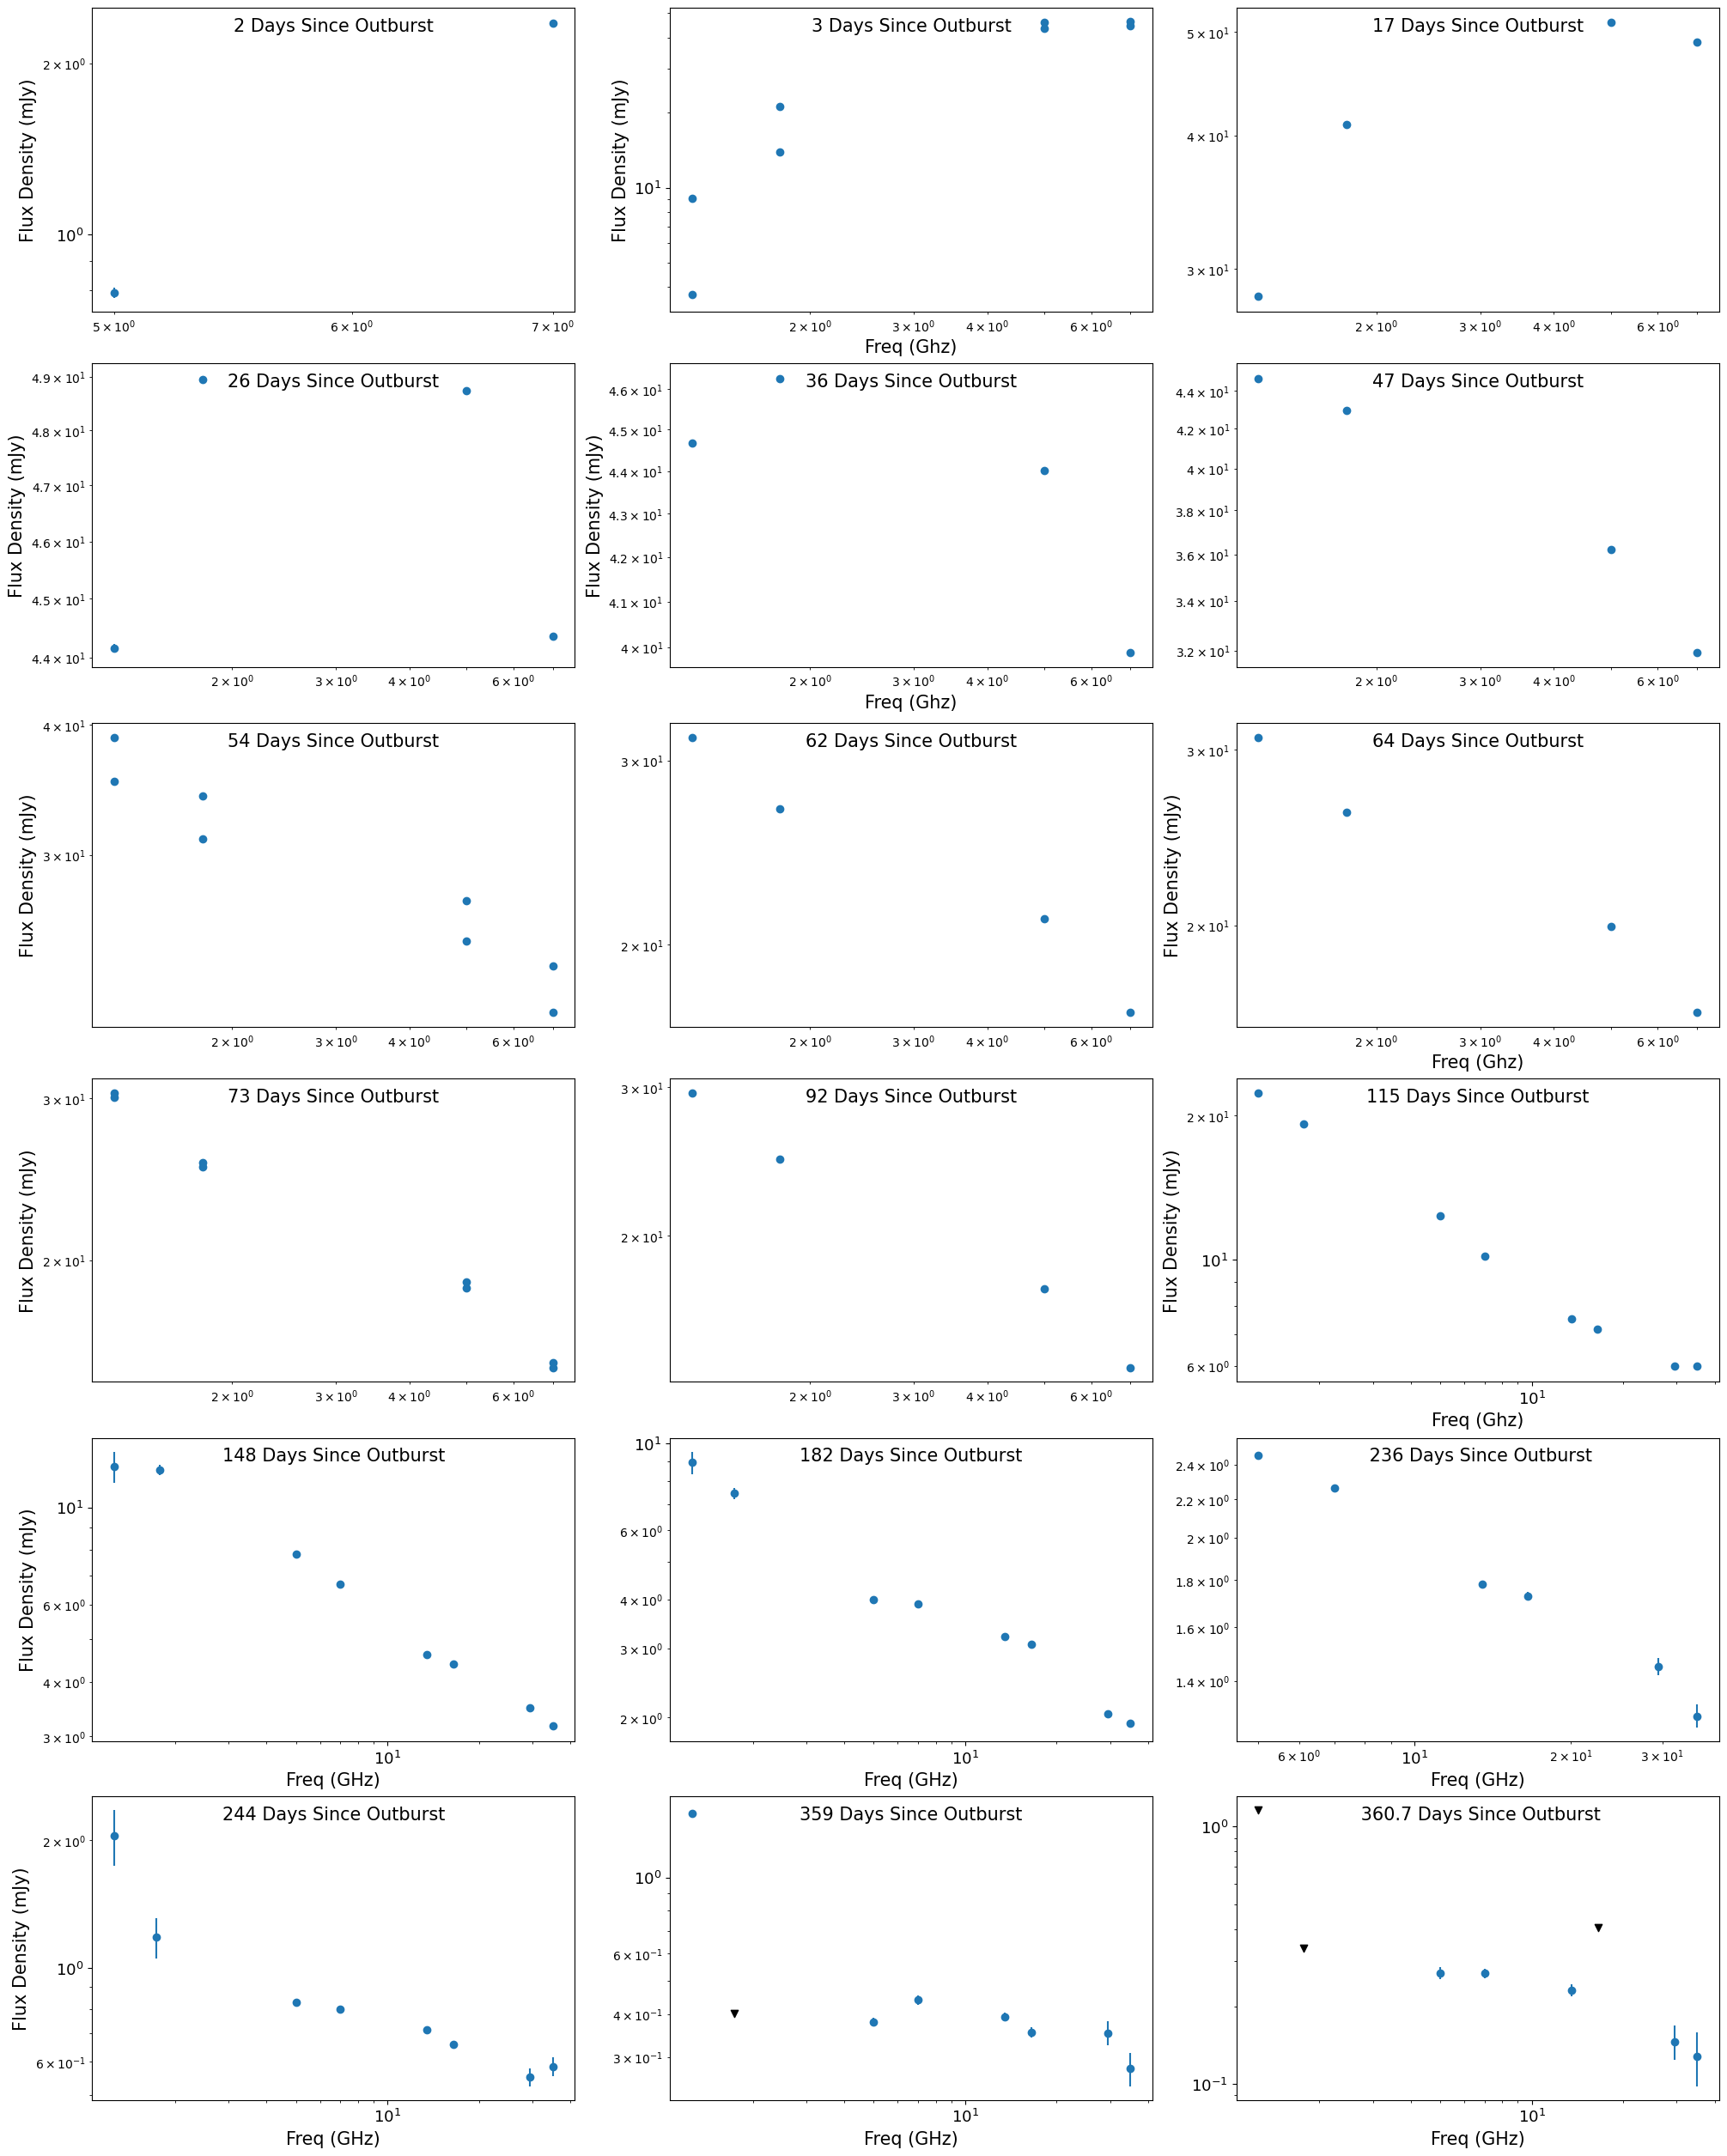

In [17]:
#Sharing x and y axis 
#Removed observation dates that only had one data point 


f, ((ax1, ax2, ax3), (ax4, ax5, ax6), (ax7, ax8, ax9),(ax10, ax11, ax12), (ax13, ax14, ax15), (ax16, ax17, ax18)) = plt.subplots(6, 3, figsize=(20, 25), sharey=False, sharex = False, constrained_layout=True)

################ Feb. 8.6  #####################
ax1.errorbar(freq_1,flux_1, yerr = err_1, linestyle = 'None', marker = 'o')
ax1.scatter(nfreq1, nflux1, marker = 'v', color = 'black', zorder = 10)
ax1.tick_params(axis='both', which='major', labelsize=13)

ax1.loglog()
ax1.set_ylabel('Flux Density (mJy)', fontsize=15)
ax1.set_title('2 Days Since Outburst', y=0.9, fontsize=15)

################     Feb. 9 and 9.6    #####################
ax2.errorbar(freq_2, flux_2, yerr = err_2, linestyle = 'None', marker = 'o')
ax2.scatter(nfreq2, nflux2, marker = 'v', color = 'black', zorder = 10)
ax2.tick_params(axis='both', which='major', labelsize=13)

ax2.loglog()
ax2.set_title('3 Days Since Outburst',  y=0.9, fontsize=15)
ax2.set_ylabel('Flux Density (mJy)', fontsize=15)
ax2.set_xlabel('Freq (Ghz)', fontsize=15)


################    Feb. 23.5    #####################
ax3.errorbar(freq_3, flux_3, yerr = err_3, linestyle = 'None', marker = 'o')
ax3.scatter(nfreq3, nflux3, marker = 'v', color = 'black', zorder = 10)
ax3.tick_params(axis='both', which='major', labelsize=13)
ax3.loglog()
ax3.set_title('17 Days Since Outburst', y=0.9, fontsize=15)


################    March 3.6    #####################
ax4.errorbar(freq_4, flux_4, yerr = err_4, linestyle = 'None', marker = 'o')
ax4.scatter(nfreq4, nflux4, marker = 'v', color = 'black', zorder = 10)
ax4.tick_params(axis='both', which='major', labelsize=13)


ax4.loglog()
ax4.set_ylabel('Flux Density (mJy)', fontsize=15)
ax4.set_title('26 Days Since Outburst', y=0.9, fontsize=15)


################    March 16.5?    #####################
ax5.errorbar(freq_5, flux_5, yerr = err_5, linestyle = 'None', marker = 'o')
ax5.scatter(nfreq5, nflux5, marker = 'v', color = 'black', zorder = 10)
ax5.tick_params(axis='both', which='major', labelsize=13)


ax5.loglog()
ax5.set_title('36 Days Since Outburst', y=0.9, fontsize=15)
ax5.set_ylabel('Flux Density (mJy)', fontsize=15)
ax5.set_xlabel('Freq (Ghz)', fontsize=15)

################    March 25.5   #####################
ax6.errorbar(freq_6, flux_6, yerr = err_6, linestyle = 'None', marker = 'o')
ax6.scatter(nfreq6, nflux6, marker = 'v', color = 'black', zorder = 10)
ax6.tick_params(axis='both', which='major', labelsize=13)
ax6.loglog()
ax6.set_title('47 Days Since Outburst', y=0.9, fontsize=15)


################    April 1    #####################
ax7.errorbar(freq_7, flux_7, yerr = err_7, linestyle = 'None', marker = 'o')
ax7.scatter(nfreq7, nflux7, marker = 'v', color = 'black', zorder = 10)
ax7.tick_params(axis='both', which='major', labelsize=13)

ax7.loglog()
ax7.set_ylabel('Flux Density (mJy)', fontsize=15)
ax7.set_title('54 Days Since Outburst', y=0.9, fontsize=15)

################    April 9.4    #####################
ax8.errorbar(freq_8, flux_8, yerr = err_8, linestyle = 'None', marker = 'o')
ax8.scatter(nfreq8, nflux8, marker = 'v', color = 'black', zorder = 10)
ax8.tick_params(axis='both', which='major', labelsize=13)


ax8.loglog()
ax8.set_title('62 Days Since Outburst', y=0.9, fontsize=15)


################    April 11    #####################
ax9.errorbar(freq_9, flux_9, yerr = err_9, linestyle = 'None', marker = 'o')
ax9.scatter(nfreq9, nflux9, marker = 'v', color = 'black', zorder = 10)
ax9.tick_params(axis='both', which='major', labelsize=13)


ax9.loglog()
ax9.set_title('64 Days Since Outburst', y=0.9, fontsize=15)
ax9.set_ylabel('Flux Density (mJy)', fontsize=15)
ax9.set_xlabel('Freq (Ghz)', fontsize=15)


################    April 20    #####################
ax10.errorbar(freq_10, flux_10, yerr = err_10, linestyle = 'None', marker = 'o')
ax10.scatter(nfreq10, nflux10, marker = 'v', color = 'black', zorder = 10)
ax10.tick_params(axis='both', which='major', labelsize=13)


ax10.loglog()
ax10.set_ylabel('Flux Density (mJy)', fontsize=15)
ax10.set_title('73 Days Since Outburst', y=0.9, fontsize=15)

################    May 9    #####################
ax11.errorbar(freq_11, flux_11, yerr = err_11, linestyle = 'None', marker = 'o')
ax11.scatter(nfreq11, nflux11, marker = 'v', color = 'black', zorder = 10)
ax11.tick_params(axis='both', which='major', labelsize=13)
ax11.loglog()
ax11.set_title('92 Days Since Outburst', y=0.9,fontsize=15)

################    June 1    #####################
ax12.errorbar(freq_12, flux_12, yerr = err_12, linestyle = 'None', marker = 'o')
ax12.scatter(nfreq12, nflux12, marker = 'v', color = 'black')
ax12.tick_params(axis='both', which='major', labelsize=13)

ax12.loglog()
ax12.set_title('115 Days Since Outburst', y=0.9, fontsize=15)
ax12.set_ylabel('Flux Density (mJy)', fontsize=15)
ax12.set_xlabel('Freq (Ghz)', fontsize=15)

################    July 3    #####################
ax13.errorbar(freq_13, flux_13, yerr = err_13, linestyle = 'None', marker = 'o')
ax13.scatter(nfreq13, nflux13, marker = 'v', color = 'black')
ax13.tick_params(axis='both', which='major', labelsize=13)

ax13.loglog()
ax13.set_ylabel('Flux Density (mJy)', fontsize=15)
ax13.set_xlabel('Freq (GHz)', fontsize=15)
ax13.set_title('148 Days Since Outburst', y=0.9, fontsize=15)

################    Aug. 7    #####################
ax14.errorbar(freq_14, flux_14, yerr = err_14, linestyle = 'None', marker = 'o')
ax14.scatter(nfreq14, nflux14, marker = 'v', color = 'black')
ax14.tick_params(axis='both', which='major', labelsize=13)

ax14.loglog()
ax14.set_xlabel('Freq (GHz)', fontsize=15)
ax14.set_title('182 Days Since Outburst', y=0.9, fontsize=15)

################    Sept. 30    #####################
ax15.errorbar(freq_15, flux_15, yerr = err_15, linestyle = 'None', marker = 'o')
ax15.scatter(nfreq15, nflux15, marker = 'v', color = 'black')
ax15.tick_params(axis='both', which='major', labelsize=13)

ax15.loglog()
ax15.set_xlabel('Freq (GHz)', fontsize=15)
ax15.set_title(' 236 Days Since Outburst', y=0.9, fontsize=15)


################    Oct. 8   #####################
ax16.errorbar(freq_16, flux_16, yerr = err_16, linestyle = 'None', marker = 'o')
ax16.scatter(nfreq16, nflux16, marker = 'v', color = 'black')
ax16.tick_params(axis='both', which='major', labelsize=13)

ax16.loglog()
ax16.set_ylabel('Flux Density (mJy)', fontsize=15)
ax16.set_xlabel('Freq (GHz)', fontsize=15)
ax16.set_title('244 Days Since Outburst', y=0.9, fontsize=15)

################    Jan 30   #####################
ax17.errorbar(freq_17, flux_17, yerr = err_17, linestyle = 'None', marker = 'o')
ax17.scatter(nfreq17, nflux17, marker = 'v', color = 'black')
ax17.tick_params(axis='both', which='major', labelsize=13)

ax17.loglog()
ax17.set_xlabel('Freq (GHz)', fontsize=15)
ax17.set_title('359 Days Since Outburst', y=0.9, fontsize=15)

################    Feb 1 2015   #####################
ax18.errorbar(freq_18, flux_18, yerr = err_18, linestyle = 'None', marker = 'o')
ax18.scatter(nfreq18, nflux18, marker = 'v', color = 'black')
ax18.tick_params(axis = 'x', which='major', labelsize=13)
ax18.tick_params(axis = 'y', which='major', labelsize=13)

ax18.loglog()
ax18.set_xlabel('Freq (GHz)', fontsize=15)
ax18.set_title(' 360.7 Days Since Outburst', y=0.9, fontsize=15)


#plt.subplots_adjust(hspace=0, wspace=0)

#plt.savefig('testplot')

plt.show()